# Projet Fil Rouge - indicateurs de naissance en France
### Mcharek, Marwa, 2026

## Data Cleaning

# Projet Fil Rouge - Indicateurs de Naissance en France

## 1. Importation des données

### Lecture du fichier Excel

In [1]:
import pandas as pd
# On importe pandas pour lire, nettoyer et analyser les données.

df = pd.read_excel(
    "../data/raw/naissances.xlsx",
    sheet_name=1,
    skiprows=5,
    header=[0, 1]
)
# On lit le fichier Excel naissances.xlsx.
# sheet_name=1 signifie qu’on lit la deuxième feuille du fichier.
# skiprows=5 permet d’ignorer les lignes de titre/description.
# header=[0, 1] indique que les noms de colonnes sont sur deux lignes.

new_columns = []
# On crée une liste vide pour stocker les nouveaux noms de colonnes.

for col in df.columns:
    # On parcourt chaque colonne du tableau.

    niveau_1 = str(col[0]).strip()
    # On récupère le premier niveau du nom de colonne, par exemple l’année 2012.

    niveau_2 = str(col[1]).strip()
    # On récupère le deuxième niveau, par exemple naissances totales.

    if "Unnamed" in niveau_1 and "Unnamed" in niveau_2:
        new_columns.append("a_supprimer")
        # Si les deux niveaux sont vides/inutiles, on marque la colonne à supprimer.

    elif "Unnamed" in niveau_1:
        new_columns.append(niveau_2)
        # Si le premier niveau est vide, on garde seulement le deuxième niveau.

    elif "Unnamed" in niveau_2:
        new_columns.append(niveau_1)
        # Si le deuxième niveau est vide, on garde seulement le premier niveau.

    else:
        new_columns.append(f"{niveau_1}_{niveau_2}")
        # Sinon, on combine les deux niveaux : année + type d’indicateur.

df.columns = new_columns
# On remplace les anciens noms de colonnes par les nouveaux noms propres.

df = df.drop(columns=["a_supprimer"], errors="ignore")
# On supprime les colonnes inutiles repérées plus haut.

df.columns = (
    df.columns
    .str.replace(" ", "_")
    .str.replace("'", "_")
    .str.lower()
)
# On nettoie les noms : espaces remplacés par _, apostrophes remplacées, tout en minuscules.


## 2. Exploration initiale des données
### Aperçu du jeu de données

In [2]:
df.head()
# On affiche les 5 premières lignes pour vérifier le résultat.

,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
0,Auvergne - Rhône-Alpes,97162.0,96344.0,95854.0,95073.0,96683.0,95926.0,94586.0,93854.0,92364.0,...,89174.0,88514.0,86542.0,85873.0,87069.0,86382.0,84877.0,84219.0,78411.0,77821.0
1,Bourgogne - Franche-Comté,31467.0,31181.0,30706.0,30459.0,30447.0,30199.0,29532.0,29295.0,28553.0,...,26304.0,26086.0,25836.0,25632.0,25558.0,25314.0,24979.0,24758.0,23348.0,23160.0
2,Bretagne,36740.0,36457.0,35861.0,35559.0,35251.0,34971.0,33712.0,33445.0,32990.0,...,31518.0,31276.0,31238.0,30991.0,32088.0,31826.0,31261.0,30991.0,29113.0,28861.0
3,Centre - Val de Loire,30217.0,29917.0,29419.0,29167.0,29225.0,28984.0,27955.0,27705.0,27478.0,...,26055.0,25823.0,25506.0,25284.0,25582.0,25382.0,25375.0,25175.0,23129.0,22906.0
4,Corse,2995.0,2960.0,2920.0,2887.0,3022.0,2981.0,2873.0,2842.0,2922.0,...,2875.0,2848.0,2682.0,2662.0,2743.0,2722.0,2744.0,2720.0,2513.0,2487.0


### Dimensions du tableau

In [3]:
df.shape
# Affiche le nombre de lignes et de colonnes.

(119, 25)

### Types des variables

In [4]:
df.info()
# Affiche les types des colonnes et les valeurs non manquantes.

<class 'pandas.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   zone_géographique         118 non-null    str    
 1   2012_naissances_totales   117 non-null    float64
 2   2012_naissances_vivantes  117 non-null    float64
 3   2013_naissances_totales   117 non-null    float64
 4   2013_naissances_vivantes  117 non-null    float64
 5   2014_naissances_totales   117 non-null    float64
 6   2014_naissances_vivantes  117 non-null    float64
 7   2015_naissances_totales   117 non-null    float64
 8   2015_naissances_vivantes  117 non-null    float64
 9   2016_naissances_totales   117 non-null    float64
 10  2016_naissances_vivantes  117 non-null    float64
 11  2017_naissances_totales   117 non-null    object 
 12  2017_naissances_vivantes  117 non-null    object 
 13  2018_naissances_totales   117 non-null    float64
 14  2018_naissances_vivan

## 3. Conversion des types de données

### Conversion des variables 2017 en numérique

In [5]:
# Conversion des colonnes 2017 en numérique.
# Ces colonnes avaient été importées en type object.
df["2017_naissances_totales"] = pd.to_numeric(
    df["2017_naissances_totales"],
    errors="coerce"
)

df["2017_naissances_vivantes"] = pd.to_numeric(
    df["2017_naissances_vivantes"],
    errors="coerce"
)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   zone_géographique         118 non-null    str    
 1   2012_naissances_totales   117 non-null    float64
 2   2012_naissances_vivantes  117 non-null    float64
 3   2013_naissances_totales   117 non-null    float64
 4   2013_naissances_vivantes  117 non-null    float64
 5   2014_naissances_totales   117 non-null    float64
 6   2014_naissances_vivantes  117 non-null    float64
 7   2015_naissances_totales   117 non-null    float64
 8   2015_naissances_vivantes  117 non-null    float64
 9   2016_naissances_totales   117 non-null    float64
 10  2016_naissances_vivantes  117 non-null    float64
 11  2017_naissances_totales   116 non-null    float64
 12  2017_naissances_vivantes  116 non-null    float64
 13  2018_naissances_totales   117 non-null    float64
 14  2018_naissances_vivan

### Recherche des valeurs manquantes

In [7]:
df.isna().sum()
# Compte les valeurs manquantes colonne par colonne.

zone_géographique           1
2012_naissances_totales     2
2012_naissances_vivantes    2
2013_naissances_totales     2
2013_naissances_vivantes    2
2014_naissances_totales     2
2014_naissances_vivantes    2
2015_naissances_totales     2
2015_naissances_vivantes    2
2016_naissances_totales     2
2016_naissances_vivantes    2
2017_naissances_totales     3
2017_naissances_vivantes    3
2018_naissances_totales     2
2018_naissances_vivantes    2
2019_naissances_totales     2
2019_naissances_vivantes    2
2020_naissances_totales     2
2020_naissances_vivantes    2
2021_naissances_totales     2
2021_naissances_vivantes    2
2022_naissances_totales     2
2022_naissances_vivantes    2
2023_naissances_totales     2
2023_naissances_vivantes    2
dtype: int64

### Identification des lignes problématiques

In [8]:
df[df.isna().any(axis=1)]
# Affiche uniquement les lignes contenant au moins une valeur manquante.
# any(axis=1) signifie :
# "au moins une cellule vide sur la ligne".

,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
14,Guadeloupe,5142.0,5057.0,5058.0,4972.0,4866.0,4787.0,4603.0,4498.0,4537.0,...,4506.0,4438.0,4666.0,4578.0,4298.0,4217.0,4089.0,4014.0,3914.0,3845.0
117,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
118,"**En 2017, les données du PMSI sont incomplète...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df.tail()
# Affiche les 5 dernières lignes du tableau.
# Permet de vérifier que les lignes 117 et 118
# sont bien les lignes de commentaire du fichier.

,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
114,Seine-Saint-Denis,28763.0,28447.0,28736.0,28426.0,29619.0,29276.0,29556.0,29235.0,29421.0,...,28579.0,28312.0,28078.0,27775.0,26554.0,26282.0,26527.0,26258.0,25320.0,25064.0
115,Val-de-Marne,20999.0,20793.0,20731.0,20548.0,21588.0,21367.0,21082.0,20904.0,20922.0,...,20733.0,20539.0,20009.0,19835.0,19740.0,19570.0,19101.0,18951.0,17818.0,17654.0
116,Val-d'Oise,19510.0,19335.0,19507.0,19318.0,19695.0,19483.0,19616.0,19394.0,19671.0,...,19805.0,19617.0,19148.0,18963.0,19256.0,19076.0,19173.0,18994.0,17970.0,17764.0
117,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
118,"**En 2017, les données du PMSI sont incomplète...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Suppression des lignes parasites

### Identification des notes PMSI

### Suppression des lignes hors données

In [10]:
df = df.iloc[:-2]
# On supprime les 2 dernières lignes :
# - ligne vide
# - note PMSI

## 5. Validation du nettoyage

### Vérification des dimensions finales

In [11]:
df.shape

# Vérifie le nombre de lignes et de colonnes.

(117, 25)

### Vérification des valeurs manquantes restantes

In [12]:
df.isna().sum()

# Vérifie les valeurs manquantes après nettoyage.

zone_géographique           0
2012_naissances_totales     0
2012_naissances_vivantes    0
2013_naissances_totales     0
2013_naissances_vivantes    0
2014_naissances_totales     0
2014_naissances_vivantes    0
2015_naissances_totales     0
2015_naissances_vivantes    0
2016_naissances_totales     0
2016_naissances_vivantes    0
2017_naissances_totales     1
2017_naissances_vivantes    1
2018_naissances_totales     0
2018_naissances_vivantes    0
2019_naissances_totales     0
2019_naissances_vivantes    0
2020_naissances_totales     0
2020_naissances_vivantes    0
2021_naissances_totales     0
2021_naissances_vivantes    0
2022_naissances_totales     0
2022_naissances_vivantes    0
2023_naissances_totales     0
2023_naissances_vivantes    0
dtype: int64

In [13]:
df.tail()
# Vérification finale du DataFrame après nettoyage.
# Les lignes de commentaire ont été supprimées.

,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
112,Essonne,18615.0,18396.0,18599.0,18429.0,18997.0,18816.0,19128.0,18935.0,18747.0,...,18585.0,18397.0,18482.0,18286.0,18538.0,18353.0,18385.0,18223.0,17263.0,17084.0
113,Hauts-de-Seine,24899.0,24647.0,24904.0,24689.0,25015.0,24794.0,24360.0,24149.0,24370.0,...,22905.0,22717.0,21908.0,21716.0,22010.0,21838.0,21079.0,20896.0,19863.0,19713.0
114,Seine-Saint-Denis,28763.0,28447.0,28736.0,28426.0,29619.0,29276.0,29556.0,29235.0,29421.0,...,28579.0,28312.0,28078.0,27775.0,26554.0,26282.0,26527.0,26258.0,25320.0,25064.0
115,Val-de-Marne,20999.0,20793.0,20731.0,20548.0,21588.0,21367.0,21082.0,20904.0,20922.0,...,20733.0,20539.0,20009.0,19835.0,19740.0,19570.0,19101.0,18951.0,17818.0,17654.0
116,Val-d'Oise,19510.0,19335.0,19507.0,19318.0,19695.0,19483.0,19616.0,19394.0,19671.0,...,19805.0,19617.0,19148.0,18963.0,19256.0,19076.0,19173.0,18994.0,17970.0,17764.0


In [14]:
# Une valeur manquante subsiste pour l'année 2017.
# Cela est cohérent avec la note du fichier PMSI indiquant
# que les données 2017 sont incomplètes.

### Résumé statistique

In [15]:
df.describe()  # Permet d'obtenir un résumé statistique des données numériques :
               # count = nombre de valeurs
               # mean = moyenne
               # std = écart-type
               # min / max = valeurs extrêmes
               # 25%, 50%, 75% = quartiles

,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,2016_naissances_vivantes,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
count,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,...,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000
mean,28080.487179,27822.709402,27776.461538,27528.641026,27747.700855,27505.111111,27067.692308,26829.290598,26565.213675,26331.333333,...,25461.641026,25247.726496,24867.487179,24648.888889,25037.487179,24817.358974,24526.914530,24313.179487,22801.589744,22602.555556
std,106339.883568,105368.273496,105237.215813,104303.976724,105159.236033,104243.339245,102525.758722,101628.538126,100615.564339,99734.252390,...,96398.305541,95593.735526,94139.719560,93317.924327,94691.447589,93865.129554,92753.382408,91950.933818,86199.378033,85451.016940
min,701.000000,699.000000,654.000000,653.000000,660.000000,652.000000,694.000000,685.000000,662.000000,659.000000,...,584.000000,580.000000,518.000000,513.000000,611.000000,609.000000,587.000000,581.000000,557.000000,553.000000
25%,3527.000000,3498.000000,3469.000000,3442.000000,3382.000000,3355.000000,3232.000000,3208.000000,3210.000000,3187.000000,...,2982.000000,2965.000000,2942.000000,2918.000000,2940.000000,2915.000000,2910.000000,2889.000000,2690.000000,2670.000000
50%,6809.000000,6755.000000,6710.000000,6648.000000,6688.000000,6643.000000,6561.000000,6497.000000,6384.000000,6329.000000,...,5967.000000,5931.000000,5971.000000,5924.000000,6002.000000,5949.000000,5828.000000,5778.000000,5405.000000,5372.000000
75%,16470.000000,16328.000000,16432.000000,16288.000000,16776.000000,16629.000000,16396.000000,16267.000000,16138.000000,16015.000000,...,15716.000000,15588.000000,15404.000000,15269.000000,15435.000000,15304.000000,15162.000000,15022.000000,14155.000000,14046.000000
max,830758.000000,823085.000000,821598.000000,814216.000000,820800.000000,813583.000000,801271.000000,794160.000000,786629.000000,779655.000000,...,754509.000000,748121.000000,736867.000000,730337.000000,742341.000000,735760.000000,727143.000000,720752.000000,676380.000000,670434.000000


## 6. Sauvegarde des données nettoyées

In [16]:
df.to_csv(
    "../data/processed/naissances_clean.csv",
    index=False
)

# Sauvegarde le DataFrame nettoyé dans le dossier processed.
# index=False évite d'ajouter une colonne d'index inutile.

## Structuration géographique des données

### Analyse de la structure géographique

Avant de séparer les données, j'examine les valeurs de la colonne
`zone_géographique` afin d'identifier les différents niveaux géographiques
présents dans le fichier.

In [17]:
df["zone_géographique"].tolist()

['Auvergne -  Rhône-Alpes',
 'Bourgogne -  Franche-Comté',
 'Bretagne',
 'Centre -  Val de Loire',
 'Corse',
 'Grand Est',
 'Hauts-de-France',
 'Ile-de-France',
 'Normandie',
 'Nouvelle-Aquitaine',
 'Occitanie',
 'Pays de la Loire',
 "Provence - Alpes - Côte d'Azur",
 'Total métropole',
 'Guadeloupe',
 'Guyane',
 'La Réunion',
 'Martinique',
 'Mayotte',
 'Total DROM',
 'Total France entière',
 'Ain',
 'Aisne',
 'Allier',
 'Alpes-de-Haute-Provence',
 'Hautes-Alpes',
 'Alpes-Maritimes',
 'Ardèche',
 'Ardennes',
 'Ariège',
 'Aube',
 'Aude',
 'Aveyron',
 'Bouches-du-Rhône',
 'Calvados',
 'Cantal',
 'Charente',
 'Charente-Maritime',
 'Cher',
 'Corrèze',
 "Côte-d'Or",
 "Côtes-d'Armor",
 'Creuse',
 'Dordogne',
 'Doubs',
 'Drôme',
 'Eure',
 'Eure-et-Loir',
 'Finistère',
 'Corse-du-Sud',
 'Haute-Corse',
 'Gard',
 'Haute-Garonne',
 'Gers',
 'Gironde',
 'Hérault',
 'Ille-et-Vilaine',
 'Indre',
 'Indre-et-Loire',
 'Isère',
 'Jura',
 'Landes',
 'Loir-et-Cher',
 'Loire',
 'Haute-Loire',
 'Loire-Atla

### Observation

La colonne contient :
- les régions françaises ;
- les départements ;
- les DROM ;
- des lignes de synthèse (Total métropole, Total DROM, Total France entière).

Une séparation des données est donc nécessaire pour faciliter les analyses.

## 7. Création du DataFrame France entière

In [18]:
# Création du DataFrame France
df_france = df[
    df["zone_géographique"] == "Total France entière"
]

# Conserve uniquement la ligne correspondant à la France entière.
df_france["zone_géographique"].tolist()

['Total France entière']

## 8. Création du DataFrame Régions

In [19]:
# Création du DataFrame Régions
regions = [
    "Auvergne -  Rhône-Alpes",
    "Bourgogne -  Franche-Comté",
    "Bretagne",
    "Centre -  Val de Loire",
    "Corse",
    "Grand Est",
    "Hauts-de-France",
    "Ile-de-France",
    "Normandie",
    "Nouvelle-Aquitaine",
    "Occitanie",
    "Pays de la Loire",
    "Provence - Alpes - Côte d'Azur",
    "Guadeloupe",
    "Guyane",
    "La Réunion",
    "Martinique",
    "Mayotte"
]

df_regions = df[
    df["zone_géographique"].isin(regions)
]

# Conserve uniquement les régions.# Création du DataFrame France
df_regions["zone_géographique"].tolist()

['Auvergne -  Rhône-Alpes',
 'Bourgogne -  Franche-Comté',
 'Bretagne',
 'Centre -  Val de Loire',
 'Corse',
 'Grand Est',
 'Hauts-de-France',
 'Ile-de-France',
 'Normandie',
 'Nouvelle-Aquitaine',
 'Occitanie',
 'Pays de la Loire',
 "Provence - Alpes - Côte d'Azur",
 'Guadeloupe',
 'Guyane',
 'La Réunion',
 'Martinique',
 'Mayotte']

## 9. Création du DataFrame Départements

In [20]:
# Création du DataFrame Départements
df_departements = df[
    ~df["zone_géographique"].isin(regions)
]

# Exclut les régions.

In [21]:
df_departements = df_departements[
    ~df_departements["zone_géographique"].isin(
        [
            "Total métropole",
            "Total DROM",
            "Total France entière"
        ]
    )
]
df_departements["zone_géographique"].tolist()

['Ain',
 'Aisne',
 'Allier',
 'Alpes-de-Haute-Provence',
 'Hautes-Alpes',
 'Alpes-Maritimes',
 'Ardèche',
 'Ardennes',
 'Ariège',
 'Aube',
 'Aude',
 'Aveyron',
 'Bouches-du-Rhône',
 'Calvados',
 'Cantal',
 'Charente',
 'Charente-Maritime',
 'Cher',
 'Corrèze',
 "Côte-d'Or",
 "Côtes-d'Armor",
 'Creuse',
 'Dordogne',
 'Doubs',
 'Drôme',
 'Eure',
 'Eure-et-Loir',
 'Finistère',
 'Corse-du-Sud',
 'Haute-Corse',
 'Gard',
 'Haute-Garonne',
 'Gers',
 'Gironde',
 'Hérault',
 'Ille-et-Vilaine',
 'Indre',
 'Indre-et-Loire',
 'Isère',
 'Jura',
 'Landes',
 'Loir-et-Cher',
 'Loire',
 'Haute-Loire',
 'Loire-Atlantique',
 'Loiret',
 'Lot',
 'Lot-et-Garonne',
 'Lozère',
 'Maine-et-Loire',
 'Manche',
 'Marne',
 'Haute-Marne',
 'Mayenne',
 'Meurthe-et-Moselle',
 'Meuse',
 'Morbihan',
 'Moselle',
 'Nièvre',
 'Nord',
 'Oise',
 'Orne',
 'Pas-de-Calais',
 'Puy-de-Dôme',
 'Pyrénées-Atlantiques',
 'Hautes-Pyrénées',
 'Pyrénées-Orientales',
 'Bas-Rhin',
 'Haut-Rhin',
 'Rhône',
 'Haute-Saône',
 'Saône-et-Loire',

## 10. Contrôle des jeux de données créés

In [22]:
# =====================================================
# Structuration géographique des données
# =====================================================

# Les données contiennent :
# - une ligne France entière
# - les régions
# - les départements
#
# Je sépare ces niveaux géographiques
# afin de faciliter les futures analyses
# et visualisations.
print("France :", df_france.shape)
print("Régions :", df_regions.shape)
print("Départements :", df_departements.shape)

France : (1, 25)
Régions : (18, 25)
Départements : (96, 25)


## 11. Sauvegarde des données nettoyées

In [23]:
df_france.to_csv("../data/processed/naissances_france.csv", index=False)

df_regions.to_csv("../data/processed/naissances_regions.csv", index=False)

df_departements.to_csv("../data/processed/naissances_departements.csv", index=False)

In [24]:
# Vérification finale

print("France")
display(df_france.head())

print("Régions")
display(df_regions.head())

print("Départements")
display(df_departements.head())

France


,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
20,Total France entière,830758.0,823085.0,821598.0,814216.0,820800.0,813583.0,801271.0,794160.0,786629.0,...,754509.0,748121.0,736867.0,730337.0,742341.0,735760.0,727143.0,720752.0,676380.0,670434.0


Régions


,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
0,Auvergne - Rhône-Alpes,97162.0,96344.0,95854.0,95073.0,96683.0,95926.0,94586.0,93854.0,92364.0,...,89174.0,88514.0,86542.0,85873.0,87069.0,86382.0,84877.0,84219.0,78411.0,77821.0
1,Bourgogne - Franche-Comté,31467.0,31181.0,30706.0,30459.0,30447.0,30199.0,29532.0,29295.0,28553.0,...,26304.0,26086.0,25836.0,25632.0,25558.0,25314.0,24979.0,24758.0,23348.0,23160.0
2,Bretagne,36740.0,36457.0,35861.0,35559.0,35251.0,34971.0,33712.0,33445.0,32990.0,...,31518.0,31276.0,31238.0,30991.0,32088.0,31826.0,31261.0,30991.0,29113.0,28861.0
3,Centre - Val de Loire,30217.0,29917.0,29419.0,29167.0,29225.0,28984.0,27955.0,27705.0,27478.0,...,26055.0,25823.0,25506.0,25284.0,25582.0,25382.0,25375.0,25175.0,23129.0,22906.0
4,Corse,2995.0,2960.0,2920.0,2887.0,3022.0,2981.0,2873.0,2842.0,2922.0,...,2875.0,2848.0,2682.0,2662.0,2743.0,2722.0,2744.0,2720.0,2513.0,2487.0


Départements


,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
21,Ain,7295.0,7231.0,7371.0,7316.0,7419.0,7367.0,7065.0,7008.0,7190.0,...,6946.0,6901.0,6877.0,6817.0,7044.0,6993.0,6891.0,6842.0,6326.0,6293.0
22,Aisne,6809.0,6748.0,6633.0,6574.0,6484.0,6430.0,6265.0,6215.0,5871.0,...,5464.0,5406.0,5374.0,5338.0,5374.0,5333.0,5416.0,5362.0,5139.0,5081.0
23,Allier,3303.0,3275.0,3217.0,3192.0,3168.0,3145.0,3031.0,3000.0,3028.0,...,2788.0,2765.0,2621.0,2592.0,2784.0,2763.0,2644.0,2619.0,2494.0,2476.0
24,Alpes-de-Haute-Provence,1542.0,1530.0,1611.0,1600.0,1528.0,1503.0,1486.0,1468.0,1464.0,...,1357.0,1346.0,1315.0,1303.0,1422.0,1415.0,1352.0,1347.0,1270.0,1256.0
25,Hautes-Alpes,1456.0,1438.0,1422.0,1408.0,1406.0,1391.0,1351.0,1340.0,1316.0,...,1249.0,1240.0,1188.0,1172.0,1277.0,1261.0,1249.0,1242.0,1089.0,1083.0


## Data Visualisation
Ici, vous réaliserez vos observations, créerez vos graphes dans un premier temps. Une fois qu'ils seront fait, ils seront à intégrer à votre application Streamlit. Considérez donc cet espace comme un bac à sable avant de vous lancer dans le développement de l'application de Data Visualisation.

## 1. Évolution des naissances en France entière

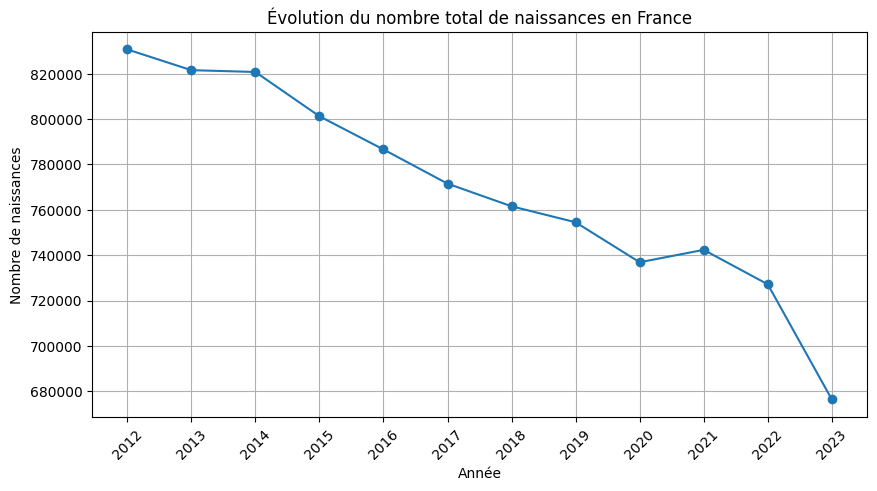

In [25]:

import matplotlib.pyplot as plt
# On importe matplotlib pour créer des graphiques.

# =====================================================
# ÉVOLUTION DES NAISSANCES EN FRANCE ENTIÈRE
# =====================================================

colonnes_totales = [
    col for col in df_france.columns
    if "naissances_totales" in col
]
# On sélectionne uniquement les colonnes qui contiennent
# les naissances totales.

annees = [
    col.split("_")[0]
    for col in colonnes_totales
]
# On récupère uniquement l'année dans le nom de colonne.
# Exemple : "2012_naissances_totales" devient "2012".

valeurs = df_france[colonnes_totales].iloc[0]
# df_france contient une seule ligne : Total France entière.
# iloc[0] permet donc de récupérer cette ligne.

plt.figure(figsize=(10, 5))
# On crée une figure de taille 10 x 5.

plt.plot(
    annees,
    valeurs,
    marker="o"
)
# On crée une courbe :
# - axe X = années
# - axe Y = nombre de naissances
# - marker="o" ajoute un point sur chaque année.

plt.title("Évolution du nombre total de naissances en France")
# Titre du graphique.

plt.xlabel("Année")
# Nom de l'axe horizontal.

plt.ylabel("Nombre de naissances")
# Nom de l'axe vertical.

plt.xticks(rotation=45)
# Incline les années pour améliorer la lisibilité.

plt.grid(True)
# Ajoute une grille pour faciliter la lecture.

plt.show()
# Affiche le graphique.


### Analyse du graphique

Le nombre total de naissances en France diminue globalement entre 2012 et 2023.

On observe une baisse quasi continue sur l'ensemble de la période, passant d'environ 830 000 naissances en 2012 à moins de 680 000 en 2023.

Une légère hausse apparaît en 2021, mais elle reste insuffisante pour inverser la tendance générale.

Cette évolution traduit une diminution de la natalité en France au cours de la dernière décennie.

## 2. Comparaison des naissances par région en 2023
Cette visualisation compare le nombre total de naissances observées dans les régions françaises en 2023.

L'objectif est d'identifier les territoires enregistrant le plus grand nombre de naissances et de mettre en évidence les écarts démographiques entre les régions.

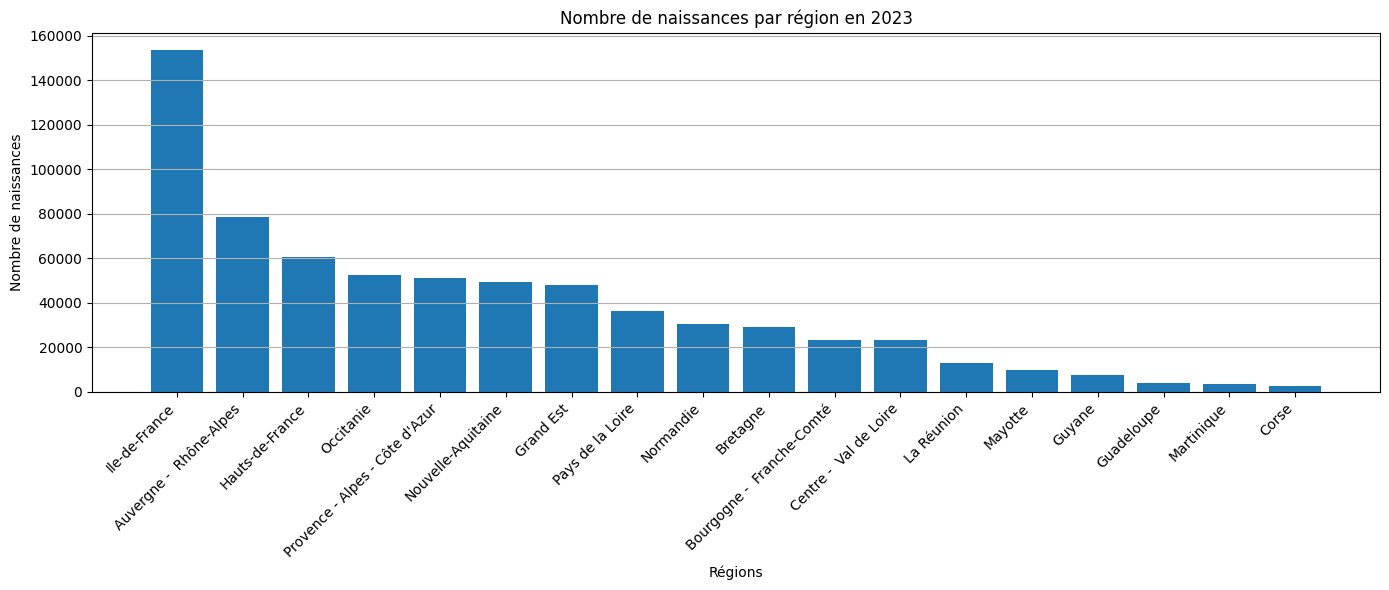

In [26]:
import matplotlib.pyplot as plt

# =====================================================
# COMPARAISON DES NAISSANCES PAR RÉGION EN 2023
# =====================================================

# Tri des régions par nombre de naissances

df_regions_2023 = df_regions.sort_values(
    by="2023_naissances_totales",
    ascending=False
)

# Création du graphique

plt.figure(figsize=(14, 6))

plt.bar(
    df_regions_2023["zone_géographique"],
    df_regions_2023["2023_naissances_totales"]
)

# Titre

plt.title("Nombre de naissances par région en 2023")

# Noms des axes

plt.xlabel("Régions")
plt.ylabel("Nombre de naissances")

# Rotation des noms de régions

plt.xticks(rotation=45, ha="right")

# Grille horizontale

plt.grid(axis="y")

# Ajuste automatiquement les marges

plt.tight_layout()

plt.show()

### Analyse du graphique

L'Île-de-France apparaît comme la région enregistrant le plus grand nombre de naissances en 2023.

Les régions les plus peuplées telles que l'Auvergne-Rhône-Alpes, les Hauts-de-France, la Nouvelle-Aquitaine et l'Occitanie présentent également un nombre élevé de naissances.

À l'inverse, les régions ultramarines et la Corse enregistrent les effectifs les plus faibles.

Ces écarts reflètent principalement les différences de population entre les territoires français.

## 3. Évolution des naissances en Île-de-France entre 2012 et 2023

L'objectif est d'étudier l'évolution du nombre total de naissances en Île-de-France entre 2012 et 2023.

L'Île-de-France étant la région la plus peuplée de France, son évolution démographique constitue un indicateur important pour comprendre les tendances nationales.

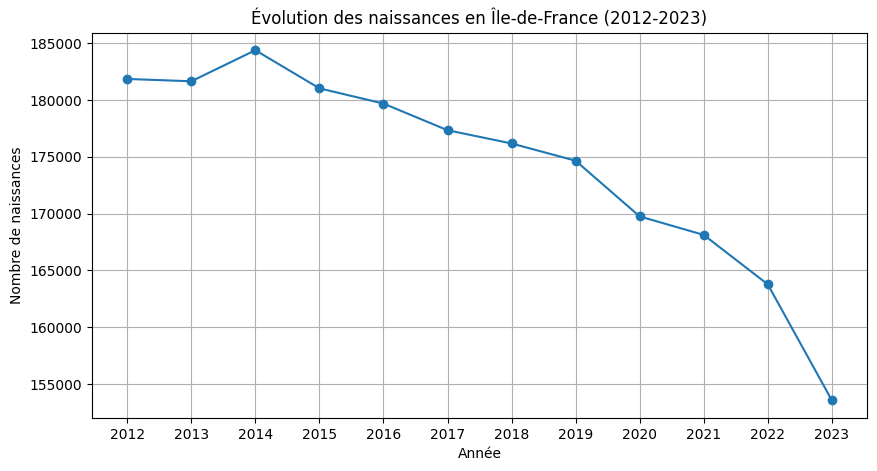

In [27]:
import matplotlib.pyplot as plt

# =====================================================
# ÉVOLUTION DES NAISSANCES EN ÎLE-DE-FRANCE
# =====================================================

# Sélection de la ligne correspondant à l'Île-de-France

idf = df_regions[
    df_regions["zone_géographique"] == "Ile-de-France"
]

# Liste des années

annees = [
    "2012",
    "2013",
    "2014",
    "2015",
    "2016",
    "2017",
    "2018",
    "2019",
    "2020",
    "2021",
    "2022",
    "2023"
]

# Récupération des valeurs

naissances = [
    idf["2012_naissances_totales"].iloc[0],
    idf["2013_naissances_totales"].iloc[0],
    idf["2014_naissances_totales"].iloc[0],
    idf["2015_naissances_totales"].iloc[0],
    idf["2016_naissances_totales"].iloc[0],
    idf["2017_naissances_totales"].iloc[0],
    idf["2018_naissances_totales"].iloc[0],
    idf["2019_naissances_totales"].iloc[0],
    idf["2020_naissances_totales"].iloc[0],
    idf["2021_naissances_totales"].iloc[0],
    idf["2022_naissances_totales"].iloc[0],
    idf["2023_naissances_totales"].iloc[0]
]

# Création du graphique

plt.figure(figsize=(10, 5))

plt.plot(
    annees,
    naissances,
    marker="o"
)

# Titre

plt.title(
    "Évolution des naissances en Île-de-France (2012-2023)"
)

# Noms des axes

plt.xlabel("Année")
plt.ylabel("Nombre de naissances")

# Ajoute une grille

plt.grid()

# Affichage

plt.show()

### Analyse

L'Île-de-France est la région française qui enregistre le plus grand nombre de naissances.

Le graphique montre une diminution progressive des naissances entre 2014 et 2023.

Après un pic observé en 2014, le nombre de naissances diminue presque chaque année.

La baisse devient particulièrement marquée à partir de 2020 et atteint son niveau le plus faible en 2023.

Cette évolution suit la tendance observée à l'échelle nationale et témoigne d'un ralentissement de la natalité en France.

## 4. Top 10 des départements ayant enregistré le plus de naissances en 2023

L'objectif est d'identifier les départements qui enregistrent le plus grand nombre de naissances en France en 2023.

Cette analyse permet de mettre en évidence les territoires les plus dynamiques sur le plan démographique.

In [28]:
import matplotlib.pyplot as plt

# =====================================================
# TOP 10 DES DÉPARTEMENTS EN 2023
# =====================================================

# Tri des départements par nombre de naissances

top10_departements = df_departements.sort_values(
    by="2023_naissances_totales",
    ascending=False
).head(10)

# Vérification du résultat

top10_departements[
    ["zone_géographique", "2023_naissances_totales"]
]

,zone_géographique,2023_naissances_totales
80,Nord,27701.0
114,Seine-Saint-Denis,25320.0
33,Bouches-du-Rhône,23038.0
96,Paris,22437.0
90,Rhône,21647.0
113,Hauts-de-Seine,19863.0
116,Val-d'Oise,17970.0
115,Val-de-Marne,17818.0
98,Seine-et-Marne,17264.0
112,Essonne,17263.0


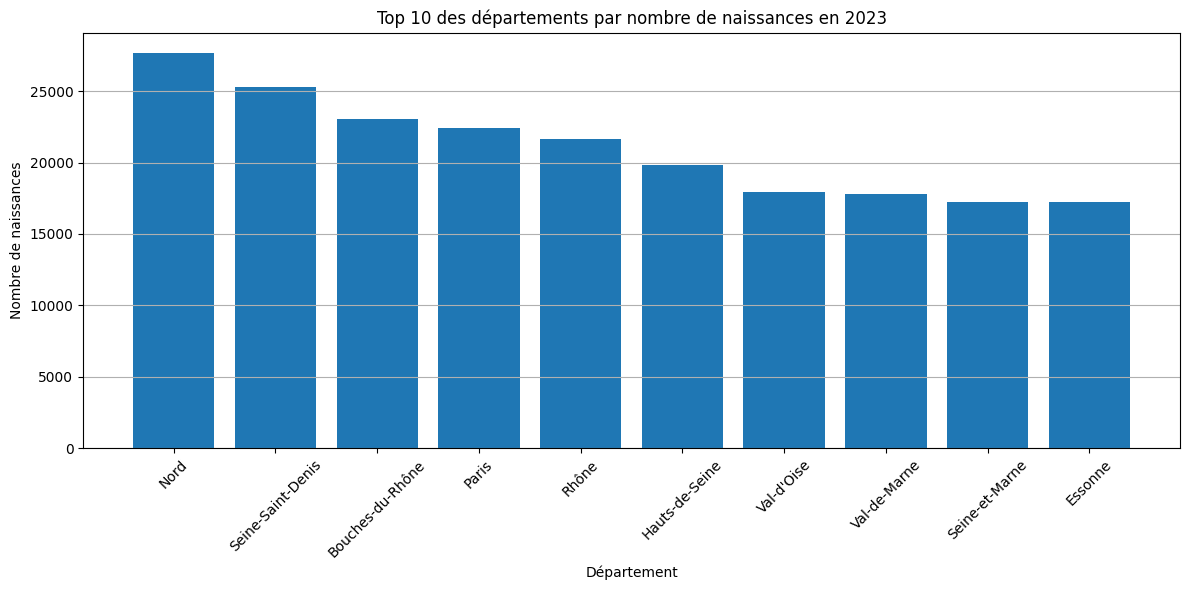

In [29]:
# Création de la figure

plt.figure(figsize=(12, 6))

# Graphique en barres verticales

plt.bar(
    top10_departements["zone_géographique"],
    top10_departements["2023_naissances_totales"]
)

# Rotation des noms

plt.xticks(rotation=45)

# Titres

plt.title(
    "Top 10 des départements par nombre de naissances en 2023"
)

plt.xlabel("Département")

plt.ylabel("Nombre de naissances")

# Ajoute une grille

plt.grid(axis="y")

# Ajuste l'affichage

plt.tight_layout()

# Affichage

plt.show()

### Analyse

Le classement met en évidence les départements enregistrant le plus grand nombre de naissances en 2023.

Les départements de l'Île-de-France occupent une place importante dans ce classement, notamment la Seine-Saint-Denis, les Hauts-de-Seine et le Val-de-Marne.

Cette concentration s'explique par la forte densité de population de la région francilienne.

Les grands départements urbains apparaissent également parmi les territoires les plus dynamiques sur le plan démographique.

## Conclusion

L'analyse des données de naissances montre une diminution progressive du nombre de naissances en France entre 2012 et 2023.

Les analyses suivantes permettront d'étudier si cette évolution s'accompagne de changements des indicateurs de santé périnatale, notamment la mortinatalité, la prématurité et le poids de naissance.